<a href="https://colab.research.google.com/github/tavishgrade/nlp-language-model-portfolio/blob/main/Talktorial_6_Sentiment_TavishGrade.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Talktorial 6 — Sentiment: Where Each Method Breaks

**Graduate NLP · Sentiment Analysis (Lecture 6) · Exposure #2** (lecture → **talktorial** → peer discussion)

In the lecture we asked whether you can just ask a language model to do sentiment analysis. Published
comparisons say a prompted model does as well as a trained one on plain positive-or-negative reviews, and worse
on sarcasm, negation and finer distinctions. In this talktorial you test that yourself. You run three systems
on the same data:

- a bag-of-words classifier trained on 1,500 movie reviews (the Pang and Lee data from the lecture)
- VADER, the rule-based lexicon from the lecture
- a small decoder model (Qwen2.5, half a billion parameters) with a zero-shot prompt and no training

Part 1 comes back to *bass*. In the Embeddings talktorial, *bass* had one vector whether it meant a fish or an
instrument. Here you look at what BERT does with it, layer by layer.

> ⚠️ **Colab users: do File → Save a copy in Drive first.** Part 1 downloads BERT (about 440 MB) and Part 3
> downloads Qwen (about 1 GB). Each takes a minute or two the first time. Everything runs on CPU; you do not
> need a GPU.

**By the end you will be able to:**
1. Measure how BERT's contextual vector for a word changes with its sentence, layer by layer
2. Train and evaluate a bag-of-words classifier, and read what it learned
3. Turn a language model's free-text answer into a label you can score
4. Write test cases that break a system, and say which kinds of cases break which system, with counts

**Submit:** answer the prediction questions below, run all cells (outputs saved), complete the
**AI Verification Log**, answer the **reflection questions** in the *Before you submit* cell, then upload the
`.ipynb` to Canvas by **Sun 11:59 PM**.

## Before you code: make some predictions

Type your answers in this cell (double-click to edit). **One or two sentences each, and every answer
needs a reason.** Predictions are graded for being real, not for being right.

- **Q1. Take BERT's vector for bass in a fishing sentence and in a music sentence. At the input layer
  the two are almost the same. At the last layer, will their cosine similarity be close to 1, close to 0,
  or in between? Give a number and a reason.**
  > *Your answer:* I think the cosine similarity will end up somewhere around 0.3-0.4 at the final layer. At the input layer, both uses of bass start with basically the same representation, but BERT is designed to pull meaning from context, so I'd expect the fishing and music versions to become much more distinct by the end of the network.
- **Q2. On ordinary movie reviews, which will score higher: a bag-of-words classifier trained on 1,500
  labelled reviews, or a half-billion-parameter language model that has seen no labelled reviews at all?
  Why?**
  > *Your answer:* My prediction is that the bag-of-words classifier will score slightly higher on standard movie reviews. It's trained directly on movie-review sentiment, while the zero-shot language model has broader knowledge but no task-specific training, and the lecture showed that LLMs tend to be strongest on simple polarity tasks but don't always outperform specialized models.
- **Q3. The lecture's predict-first slide listed four sentences. Copy your predictions from class here:
  for each sentence, the label you expect the zero-shot model to give, and the correct label.**
  *"Oh great, my flight got cancelled again. Love that for me."* · *"This drug is aggressive."* ·
  *"The food was not bad at all."* · *"We loved it, a sure guaranteed cure for insomnia."*
  > *Your answer:*
  
  
> "Oh great, my flight got cancelled again. Love that for me."
Zero-shot prediction: Positive.
Correct label: Negative.
Reason: The sentence contains obviously positive words like great and love, but they're being used sarcastically. Sarcasm was one of the main weaknesses discussed in lecture.

> "This drug is aggressive."
Zero-shot prediction: Negative.
Correct label: Neutral (or context-dependent).
Reason: I think the model will associate aggressive with something negative, even though the lecture pointed out that this example can reasonably be interpreted as positive, negative, or neutral depending on context.

> "The food was not bad at all."
Zero-shot prediction: Positive.
Correct label: Positive.
Reason: The model will probably get this one right because the negation is fairly straightforward, and modern systems usually handle common examples like "not bad" better than sarcasm.

> "We loved it, a sure guaranteed cure for insomnia."
Zero-shot prediction: Positive.
Correct label: Negative.
Reason: The phrase starts with highly positive language, but the real meaning is that the movie was boring. I expect the sarcasm to be harder for the model to detect than the literal positive wording.

## Part 0 — Setup

Provided. Imports what we use (safe to re-run). `torch`, `transformers` and `scikit-learn` are
preinstalled on Colab; `nltk` downloads two small data files.

> **Colab:** if an install finishes with a message asking you to **restart the runtime**, do that
> (**Runtime → Restart session**) and run this cell again. That is normal, not an error.

In [ ]:
import json, os, random, time   # json/os are used by the artifact cell in Part 6
import importlib.util, subprocess, sys
for pkg in ("torch", "transformers", "sklearn", "nltk", "matplotlib"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "scikit-learn" if pkg == "sklearn" else pkg])

import numpy as np
import torch
import matplotlib.pyplot as plt
import nltk
import transformers
transformers.logging.set_verbosity_error()     # hide the download/load chatter; errors still show
nltk.download("movie_reviews", quiet=True)
nltk.download("vader_lexicon", quiet=True)
np.set_printoptions(precision=3, suppress=True)
torch.manual_seed(0); np.random.seed(0)
print("torch", torch.__version__, "· numpy", np.__version__, "· nltk", nltk.__version__, "ready")

torch 2.11.0+cpu · numpy 2.1.3 · nltk 3.9.1 ready


## Part 1 — Bass, one more time

In the Embeddings talktorial, *bass* had one vector, whatever it meant. BERT gives every word a new vector at
every layer, built from the words around it by attention. That is the computation you did by hand in
Talktorial 5, and that we stepped through in the lecture.

`bert-base-uncased` has an input layer (layer 0: the token embedding plus the position embedding) and 12
Transformer layers. With `output_hidden_states=True` it returns all 13, each of shape (tokens × 768).

We use four sentences, two for each sense:

| name | sentence |
|---|---|
| fish1 | He landed a bass in the river. |
| fish2 | The bass swam slowly under the boat. |
| music1 | He plucked the bass to the song. |
| music2 | She tuned the bass before the concert. |

`bass_by_layer(sentence)` is provided. It runs BERT, finds the token `bass`, and returns its vector at every
layer as an array of shape (13, 768). You write `cosine(a, b)` and build the table.

In [ ]:
from transformers import AutoTokenizer, AutoModel
bert_tok = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased", output_hidden_states=True).eval()
SENTS = {"fish1": "He landed a bass in the river.", "fish2": "The bass swam slowly under the boat.",
         "music1": "He plucked the bass to the song.", "music2": "She tuned the bass before the concert."}
print("BERT loaded:", bert.config.num_hidden_layers, "layers,", bert.config.hidden_size, "dimensions")

def bass_by_layer(sentence):
    """Return bass's vector at every layer: a numpy array of shape (13, 768)."""
    enc = bert_tok(sentence, return_tensors="pt")
    pos = enc["input_ids"][0].tolist().index(bert_tok.convert_tokens_to_ids("bass"))   # [CLS] counts as 0
    with torch.no_grad():
        hidden = bert(**enc).hidden_states                       # 13 tensors, each (1, tokens, 768)
    return np.stack([h[0, pos].numpy() for h in hidden])

V = {name: bass_by_layer(s) for name, s in SENTS.items()}
print("bass vectors:", {name: v.shape for name, v in V.items()})

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BERT loaded: 12 layers, 768 dimensions
bass vectors: {'fish1': (13, 768), 'fish2': (13, 768), 'music1': (13, 768), 'music2': (13, 768)}


In [ ]:
# TODO: write cosine(a, b), then print the table.
#   cosine(a, b): dot product divided by the product of the norms. Return a plain float.
# V["fish1"][L] is bass's vector at layer L in the sentence fish1 (V is built in the cell above).
# For every layer L = 0..12, print three columns: fish1-fish2, music1-music2, and the MEAN of the four fish-music
# pairs. Keep the three columns in lists named same_fish, same_music and cross (the plot and the check cell use them).
def cosine(a, b):
    # cosine similarity = dot product / lengths
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

# store results for each layer
same_fish = []
same_music = []
cross = []

print(f"{'L':<3} {'fish-fish':>10} {'music-music':>12} {'fish-music':>12}")

# BERT gives us 13 representations:
# layer 0 = input embedding
# layers 1-12 = transformer layers
for L in range(13):

    # compare fish meaning to fish meaning
    fish = cosine(
        V["fish1"][L],
        V["fish2"][L]
    )

    # compare music meaning to music meaning
    music = cosine(
        V["music1"][L],
        V["music2"][L]
    )

    # compare fish meaning to music meaning
    # average all four possible fish/music combinations
    cross_mean = np.mean([
        cosine(V["fish1"][L], V["music1"][L]),
        cosine(V["fish1"][L], V["music2"][L]),
        cosine(V["fish2"][L], V["music1"][L]),
        cosine(V["fish2"][L], V["music2"][L])
    ])

    # save for later plotting
    same_fish.append(fish)
    same_music.append(music)
    cross.append(cross_mean)

    # print one row per layer
    print(f"{L:<3} {fish:>10.3f} {music:>12.3f} {cross_mean:>12.3f}")

L    fish-fish  music-music   fish-music
0        0.949        1.000        0.974
1        0.910        0.954        0.875
2        0.891        0.958        0.793
3        0.849        0.929        0.741
4        0.805        0.931        0.713
5        0.757        0.928        0.697
6        0.762        0.931        0.704
7        0.757        0.916        0.687
8        0.777        0.902        0.681
9        0.762        0.895        0.640
10       0.792        0.880        0.619
11       0.822        0.888        0.619
12       0.717        0.866        0.551


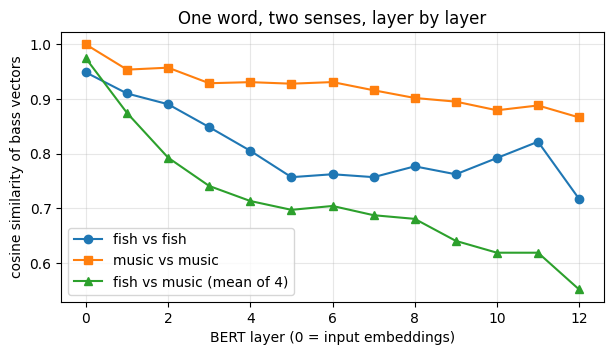

Part 1 OK — layer 12: fish-fish 0.717, music-music 0.866, fish-music 0.551


In [ ]:
# Provided: does your code meet its contract? (If this fails, fix the cell above.)
assert V["fish1"].shape == (13, 768), f"bass_by_layer should return shape (13, 768), got {V['fish1'].shape}"
assert abs(cosine(np.array([1., 0.]), np.array([1., 1.])) - 0.7071) < 1e-3, "cosine([1,0],[1,1]) should be 0.707"
assert len(cross) == 13 and cross[0] > 0.9, "the cross-sense column should start above 0.9 at layer 0"
assert cross[12] < same_music[12], "at the last layer the two senses should be further apart than two music uses"
plt.figure(figsize=(7, 3.5))
plt.plot(same_fish, "o-", label="fish vs fish"); plt.plot(same_music, "s-", label="music vs music")
plt.plot(cross, "^-", label="fish vs music (mean of 4)")
plt.xlabel("BERT layer (0 = input embeddings)"); plt.ylabel("cosine similarity of bass vectors")
plt.title("One word, two senses, layer by layer"); plt.legend(); plt.grid(alpha=.3); plt.show()
print("Part 1 OK — layer 12: fish-fish %.3f, music-music %.3f, fish-music %.3f" % (same_fish[12], same_music[12], cross[12]))

**Was Q1 right? Quote the cross-sense number at layer 0 and at layer 12, and the two same-sense numbers at
layer 12. Why does the cross-sense number only mean something next to the same-sense ones?**
> *Your answer:* My prediction was mostly right. The cross-sense similarity started at 0.974 in layer 0 and dropped to 0.551 by layer 12. At layer 12, the same-sense similarities were 0.717 for fish-fish and 0.866 for music-music. The drop in the cross-sense score shows that BERT is separating the fish and music meanings of bass as it incorporates context from surrounding words. However, the cross-sense number only makes sense when compared to the same-sense numbers. A value of 0.551 by itself still indicates some similarity, but since it is noticeably lower than both same-sense scores, it shows that BERT considers the fish and music uses more different from each other than two examples of the same meaning.

### ✅ Verification checkpoint #1
Ask your AI assistant: *"Does BERT give the same vector to the same word in different sentences?"* Check its
answer against your own Part 1 table and plot first, then against the BERT by hand slides in the lecture. If it
says the vectors differ, check by how much and at which layers. Record it in Part 5.

## Part 2 — A classical classifier

NLTK's `movie_reviews` is the Pang and Lee polarity dataset from the lecture: 2,000 movie reviews, 1,000
positive and 1,000 negative. The cell below splits it 75/25 (with a fixed seed, so everyone gets the same split)
and turns each review into binary unigram features: does each word occur in the review or not. That is the
setting that did best in Pang et al. (2002). You then train two classifiers on it: Naive Bayes and logistic
regression (the MaxEnt from the lecture).

In [ ]:
from nltk.corpus import movie_reviews as mr
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

docs = [(mr.raw(f), c) for c in mr.categories() for f in mr.fileids(c)]
X = [d for d, _ in docs]
y = [1 if c == "pos" else 0 for _, c in docs]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=516, stratify=y)
vectorizer = CountVectorizer(binary=True, min_df=2)       # presence, not counts; drop words seen in one review
A_train = vectorizer.fit_transform(X_train)               # fit on the training texts only
A_test = vectorizer.transform(X_test)
print(f"{len(X_train)} training reviews, {len(X_test)} test reviews, {A_train.shape[1]:,} features")

1500 training reviews, 500 test reviews, 21,190 features


In [ ]:
# TODO: train two classifiers on A_train / y_train and report their accuracy on A_test / y_test.
#   nb = MultinomialNB().fit(...);  lr = LogisticRegression(max_iter=2000).fit(...)
#   acc_nb and acc_lr = the fraction of test reviews each gets right (plain floats), printed.
# Keep the names nb, lr, acc_nb, acc_lr -- later cells use them.
# train Naive Bayes on the training reviews
nb = MultinomialNB().fit(A_train, y_train)

# train logistic regression (MaxEnt from the lecture)
lr = LogisticRegression(max_iter=2000).fit(A_train, y_train)

# accuracy = percent of test reviews classified correctly
acc_nb = nb.score(A_test, y_test)
acc_lr = lr.score(A_test, y_test)

print(f"Naive Bayes accuracy: {acc_nb:.3f}")
print(f"Logistic Regression accuracy: {acc_lr:.3f}")

Naive Bayes accuracy: 0.806
Logistic Regression accuracy: 0.852


In [ ]:
# Provided: checks the classifiers, then shows what logistic regression learned.
assert len(X_test) == 500, "the test split should hold 500 reviews (test_size=0.25 of 2,000)"
assert 0.75 < acc_lr < 0.95 and 0.70 < acc_nb < 0.95, f"accuracies look off: NB {acc_nb}, LR {acc_lr}"
words = np.array(vectorizer.get_feature_names_out())
order = np.argsort(lr.coef_[0])
print("Most NEGATIVE words:", ", ".join(words[order[:15]]))
print("Most POSITIVE words:", ", ".join(words[order[-15:]][::-1]))
print("Part 2 OK")

Most NEGATIVE words: bad, worst, awful, unfortunately, poor, plot, nothing, boring, script, have, supposed, mess, ridiculous, wasted, looks
Most POSITIVE words: true, terrific, memorable, well, especially, different, great, fun, overall, hilarious, perfectly, makes, performances, others, solid
Part 2 OK


**Pang et al. (2002) reported 82.9% with unigram presence and an SVM. How do your two numbers compare? Then
name one word in the lists that is not a sentiment word, and say why it might still predict the label.**
> *Your answer:* My logistic regression accuracy was 85.2%, which is slightly higher than the 82.9% reported by Pang et al. (2002) for unigram presence with an SVM. My Naive Bayes accuracy was 80.6%, which was slightly lower than the Pang et al. result. Overall, both of my results were fairly close to the benchmark reported in the lecture. One example of a word that is not really a sentiment word is "performances" from the positive list. By itself, the word is neutral, but in movie reviews it often appears in positive discussions about acting and may therefore be associated with positive reviews in the training data. Similarly, words can become predictive because they occur more frequently in one class of reviews, even if they do not directly express sentiment.

## Part 3 — A language model with no training

`Qwen2.5-0.5B-Instruct` is an instruction-tuned decoder with half a billion parameters, small enough to run on a
CPU. It has never seen these reviews or their labels. You give it the zero-shot prompt from the lecture and read
the word it writes back.

`ask(text)` is provided. It puts the text into the prompt below, runs the model with greedy decoding (so it gives
the same answer every time), and returns the answer as a string. You write `to_label(answer)`, which turns that
answer into 1 (positive), 0 (negative) or None (anything else).

```
Classify the text as positive or negative. Answer with one word.
Text: <the text>
Sentiment:
```

In [ ]:
from transformers import AutoModelForCausalLM
QWEN = "Qwen/Qwen2.5-0.5B-Instruct"
qwen_tok = AutoTokenizer.from_pretrained(QWEN)
qwen = AutoModelForCausalLM.from_pretrained(QWEN).float().eval()   # .float(): newer transformers load bfloat16, slow on CPU
PROMPT = "Classify the text as positive or negative. Answer with one word.\nText: {text}\nSentiment:"
print("Qwen loaded:", sum(p.numel() for p in qwen.parameters()) / 1e6, "million parameters")

def ask(text):
    """The model's raw answer to the zero-shot prompt, as a stripped string."""
    messages = [{"role": "user", "content": PROMPT.format(text=text)}]
    enc = qwen_tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True)
    with torch.no_grad():
        out = qwen.generate(**enc, max_new_tokens=4, do_sample=False)
    return qwen_tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()   # only the new tokens

print(ask("This movie was great."), "|", ask("This movie was terrible."))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen loaded: 494.032768 million parameters
Positive | Negative


In [ ]:
# TODO: write to_label(answer):  "Positive", "positive." -> 1;  "Negative" -> 0;  anything else -> None.
# Then print to_label("Positive"), to_label(" negative.") and to_label("Neutral").
def to_label(answer):
    # remove extra spaces and punctuation
    answer = answer.strip().lower().replace(".", "")

    # convert model output into our labels
    if answer == "positive":
        return 1
    elif answer == "negative":
        return 0

    # anything else (neutral, mixed, etc.)
    return None

print(
    to_label("Positive"),
    to_label(" negative."),
    to_label("Neutral")
)

1 0 None


In [ ]:
# Provided: checks your function, then runs the model on 40 test reviews (a minute or two on Colab's CPU).
assert to_label("Positive") == 1 and to_label(" negative.") == 0 and to_label("Neutral") is None, "to_label is off"
assert to_label(ask("This movie was great.")) == 1, "the model should call 'This movie was great.' positive"
from nltk.sentiment.vader import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()
def vader_label(text):
    c = vader.polarity_scores(text)["compound"]
    return 1 if c >= 0.05 else (0 if c <= -0.05 else None)     # the cut-offs from the lecture

random.seed(516)
sample = random.sample(range(len(X_test)), 40)
first150 = lambda t: " ".join(t.split()[:150])                 # long reviews are slow on CPU: first 150 words
gold = np.array([y_test[i] for i in sample])
t0 = time.time()
llm_answers = [ask(first150(X_test[i])) for i in sample]
llm_pred = [to_label(a) for a in llm_answers]
acc_llm = float(np.mean([p == g for p, g in zip(llm_pred, gold)]))
acc_lr40 = float(np.mean(lr.predict(vectorizer.transform([X_test[i] for i in sample])) == gold))
acc_vader40 = float(np.mean([vader_label(X_test[i]) == y_test[i] for i in sample]))
print(f"40 test reviews ({time.time() - t0:.0f} s for the language model)")
print(f"  logistic regression (trained): {acc_lr40:.3f}")
print(f"  VADER (rules, full review):    {acc_vader40:.3f}")
print(f"  Qwen 0.5B zero-shot (150 words): {acc_llm:.3f}   answers seen: {sorted(set(llm_answers))}")
print("Part 3 OK")

40 test reviews (170 s for the language model)
  logistic regression (trained): 0.950
  VADER (rules, full review):    0.475
  Qwen 0.5B zero-shot (150 words): 0.750   answers seen: ['Negative', 'Positive', 'positive']
Part 3 OK


**Was Q2 right? Quote the three accuracies, and give one reason this 0.5B model might trail the trained
classifier when the lecture showed ChatGPT matching one.**
> *Your answer:* Q2 was partially right. I predicted that the bag-of-words classifier would perform slightly better than the zero-shot language model, and that is what happened. The logistic regression classifier achieved 95.0% accuracy, the Qwen 0.5B zero-shot model achieved 75.0% accuracy, and VADER achieved 47.5% accuracy on the 40-review sample. One reason the 0.5B language model may trail the trained classifier is that it was not trained specifically on the movie review dataset. The logistic regression model learned directly from 1,500 labeled training reviews, while Qwen received only a prompt and had to infer the sentiment without seeing any examples from this dataset. The lecture showed that ChatGPT can match fine-tuned models on some sentiment benchmarks, but those results were obtained with a much larger model. Qwen 0.5B is much smaller and may not have the same ability to generalize from a zero-shot prompt.

## Part 4 — Break it

One accuracy number does not tell you where a system fails. The cell below has 20 short cases, each written to
trip something up, with the label a careful reader would give and the kind of problem it tests. The first four
are the sentences from the lecture's predict-first slide. *"This drug is aggressive."* has no label on purpose:
you decide what it should be.

Add three cases of your own to `MY_CASES`: one sarcastic, one with negation, and one where a word's sentiment
depends on the domain. Then run the comparison.

In [ ]:
BREAK = [  # (text, gold label: 1 positive / 0 negative / None = you decide, kind)
    ("Oh great, my flight got cancelled again. Love that for me.", 0, "sarcasm"),
    ("This drug is aggressive.", None, "domain"),
    ("The food was not bad at all.", 1, "negation"),
    ("We loved it, a sure guaranteed cure for insomnia.", 0, "sarcasm"),
    ("Strap in for the Hobbit, the only movie trilogy that takes longer to watch than read.", 0, "sarcasm"),
    ("The end is the best part, the time you can finally go home.", 0, "sarcasm"),
    ("I don't like this book.", 0, "negation"),
    ("No wonder this is considered one of the best.", 1, "negation"),
    ("It avoids all the cliches and predictability of Hollywood movies.", 1, "negation"),
    ("The film is not good.", 0, "negation"),
    ("Nothing about this was boring.", 1, "negation"),
    ("The characters are so real that I was too scared to pick the book back up.", 1, "misleading words"),
    ("The plot is unpredictable.", 1, "domain"),
    ("The steering is unpredictable.", 0, "domain"),
    ("The battery lasts a long time.", 1, "domain"),
    ("The wait for a table lasts a long time.", 0, "domain"),
    ("They had an excellent selection and the lowest prices in town. You guys suck.", 0, "reversal"),
    ("A wonderful cast wasted on a dull script.", 0, "reversal"),
    ("This movie was great.", 1, "plain"),
    ("This movie was terrible.", 0, "plain"),
]
print(len(BREAK), "built-in cases")

20 built-in cases


In [ ]:
# TODO: three cases of your own, in the same shape as BREAK: (text, gold 1 or 0, kind).
# One "sarcasm", one "negation" and one "domain" (a word whose polarity depends on what it describes).
MY_CASES = [

    # says something positive but actually means the opposite
    ("Fantastic, another three-hour software update right before my presentation.", 0, "sarcasm"),

    # negation flips the meaning
    ("The customer service was not terrible.", 1, "negation"),

    # same word can be good or bad depending on what it describes
    ("The surgery was aggressive and removed all of the cancer.", 1, "domain")

]

In [ ]:
# Provided: runs all three systems on every case and prints the table.
assert isinstance(MY_CASES, list) and len(MY_CASES) >= 3, "add at least three cases to MY_CASES"
assert {"sarcasm", "negation", "domain"} <= {k for _, _, k in MY_CASES}, "include a sarcasm, a negation and a domain case"
name = {1: "pos", 0: "neg", None: "?"}
rows = []
for text, g, kind in BREAK + MY_CASES:
    p_lr = int(lr.predict(vectorizer.transform([text]))[0])
    p_va = vader_label(text)
    p_llm = to_label(ask(text))
    rows.append({"text": text, "gold": g, "kind": kind, "lr": p_lr, "vader": p_va, "llm": p_llm})
    print(f"{kind:16s} gold={name[g]:3s}  LR={name[p_lr]:3s} VADER={name[p_va]:3s} LLM={name[p_llm]:3s} | {text}")

kinds = sorted({r["kind"] for r in rows if r["gold"] is not None})
print(f"\n{'kind':16s} {'cases':>5} {'LR right':>9} {'VADER right':>12} {'LLM right':>10}")
for k in kinds:
    rs = [r for r in rows if r["kind"] == k and r["gold"] is not None]
    print(f"{k:16s} {len(rs):5d} {sum(r['lr'] == r['gold'] for r in rs):9d} "
          f"{sum(r['vader'] == r['gold'] for r in rs):12d} {sum(r['llm'] == r['gold'] for r in rs):10d}")

sarcasm          gold=neg  LR=pos VADER=pos LLM=neg | Oh great, my flight got cancelled again. Love that for me.
domain           gold=?    LR=pos VADER=neg LLM=neg | This drug is aggressive.
negation         gold=pos  LR=neg VADER=pos LLM=pos | The food was not bad at all.
sarcasm          gold=neg  LR=pos VADER=pos LLM=pos | We loved it, a sure guaranteed cure for insomnia.
sarcasm          gold=neg  LR=neg VADER=?   LLM=neg | Strap in for the Hobbit, the only movie trilogy that takes longer to watch than read.
sarcasm          gold=neg  LR=pos VADER=pos LLM=pos | The end is the best part, the time you can finally go home.
negation         gold=neg  LR=neg VADER=neg LLM=neg | I don't like this book.
negation         gold=pos  LR=pos VADER=pos LLM=pos | No wonder this is considered one of the best.
negation         gold=pos  LR=pos VADER=neg LLM=pos | It avoids all the cliches and predictability of Hollywood movies.
negation         gold=neg  LR=pos VADER=neg LLM=neg | The film is not

**Which of the four lecture sentences did the language model get wrong, and were your Q3 predictions right?
From the counts table, which kind of case does each system handle worst (quote the numbers)? What label would you
give "This drug is aggressive.", and why?**
> *Your answer:* Out of the four lecture sentences, the language model got two wrong. It correctly labeled "Oh great, my flight got cancelled again. Love that for me." as negative and "The food was not bad at all." as positive, which matched my Q3 predictions. However, it incorrectly labeled"We loved it, a sure guaranteed cure for insomnia." as positive instead of negative and"This drug is aggressive." as negative. My prediction for the insomnia sentence was correct, but I predicted "This drug is aggressive." would be neutral or context-dependent rather than simply negative. From the counts table, the logistic regression classifier handled domain cases worst, getting only 1 out of 5 correct. VADER also handled domain cases worst, getting 0 out of 5 correct. The language model's weakest category was sarcasm, where it got only 2 out of 5 correct. All three systems also failed the single misleading words example, scoring 0 out of 1. For "This drug is aggressive.", I would label it as neutral/context-dependent. The lecture specifically used this example to show that sentiment can depend on the speaker and situation. An oncologist might view an aggressive drug positively because it is effective against a serious illness, while a patient experiencing severe side effects might view it negatively. Without additional context, there is not enough information to assign a single clear sentiment label.

### ✅ Verification checkpoint #2
Ask your AI assistant: *"Can a large language model do sentiment analysis zero-shot as well as a trained
classifier?"* Check its answer against your own Part 3 and Part 4 results, and against the lecture's comparison
slides (Zhang et al., 2024: where prompting matches a trained model and where it trails). If the AI gives a plain
yes or no, say what your numbers add. Record it in Part 5.

## Part 5 — AI Verification Log

One block per checkpoint: the **question you asked**, the **claim** that came back, the **source** you
checked it against, your **verdict**, and **what you found when you checked** — what the source actually
said, or what your own output actually showed. Then add at least one claim you chose yourself.

**How the log is graded** — the same four rows as the assignment page:
- **The question.** A real question, and a follow-up where the first answer was thin. *"Isn't sentiment
  basically solved?"* is fishing for agreement; *"Where does zero-shot sentiment classification still fail?"* is a question.
- **Source quality.** The right kind for the kind of claim: the lecture, the textbook or the paper for a
  definition or a research finding, the library documentation for how a function behaves, **your own output**
  for a claim about what these models do on these sentences.
- **Thoroughness.** Every checkpoint, plus a claim you chose yourself.
- **What you found.** The finding says what the source *said* or what your output *showed*. Naming a
  caveat, a boundary condition, or a case where the claim breaks is what makes a block excellent
  rather than satisfactory. The AI does not have to be wrong.

*(Double-click this cell to edit. Type after each bold label, then Shift+Enter to render it.)*

**A worked example, filled in so you can see the bar.** This one is not yours to answer:

- **What you asked:** "What does VADER's compound score mean, and what threshold separates positive from negative?"
- **What it told you:** The compound score runs from -1 to +1; above 0 is positive, below 0 is negative.
- **Source checked:** The VADER README (github.com/cjhutto/vaderSentiment) and the lecture's VADER slide, plus my own Part 3 output
- **Verdict:** ⚠️ partly right
- **What you found when you checked:** The range is right: the README calls it a normalized score between -1 (most extreme negative) and +1 (most extreme positive). The threshold is not: the README and the lecture use ≥ 0.05 for positive and ≤ -0.05 for negative, with a neutral band in between. That band matters for short sentences, which often contain no word in VADER's lexicon and score exactly 0: with the AI's rule they would be forced into a label.

**The same block, written the way that does not count.** Same question, same source:

- **What you found when you checked:** The README confirms the compound score goes from -1 to 1. ✅

That repeats the claim. It does not say what the source said about the threshold, and it did not look at the
output. A finding that could have been written without opening the source is not a check.

---

### Claim 1 — checkpoint #1
- **What you asked:** "Does BERT give the same vector to the same word in different sentences?"
- **What it told you:** No. BERT gives different contextual vectors to the same word depending on the sentence. Unlike Word2Vec or GloVe, which assign one fixed vector per word, BERT uses surrounding context to create different representations.
- **Source checked:** Lecture 6 slides on BERT and contextual representations, especially the "Bass, one more time" section; my Part 1 Python output; and the BERT worked example from the lecture.
- **Verdict:** ⚠️ partly right
- **What you found when you checked:** The AI correctly stated that BERT produces contextual embeddings, so the same word can have different vectors in different sentences. However, it left out an important detail from both the lecture and my experiment: the vectors do not start out very different. In Part 1, the cross-sense similarity for bass was 0.974 at layer 0, showing that the fish and music meanings were almost identical at the input layer. By layer 12, the cross-sense similarity dropped to 0.551, while the same-sense similarities remained higher (0.717 for fish-fish and 0.866 for music-music). My output showed that BERT gradually separates the meanings across its Transformer layers as it incorporates context, rather than assigning completely different vectors from the start. The lecture's BERT walkthrough also emphasized that each layer builds a more contextualized representation using attention over surrounding words.

### Claim 2 — checkpoint #2
- **What you asked:** "Can a large language model do sentiment analysis zero-shot as well as a trained classifier?"
- **What it told you:** Yes, in some situations. Zero-shot LLMs can be competitive with trained classifiers, but performance depends on the model, dataset, and task. Trained classifiers may perform better for domain-specific data, consistent labeling, or large-scale deployment.
- **Source checked:** Lecture 6 comparison slides on zero-shot prompting versus trained models, especially the Zhang et al. (2024) results; my Part 3 sentiment-analysis results; and my Part 4 error analysis.
- **Verdict:** ⚠️ partly right
- **What you found when you checked:** The AI correctly stated that zero-shot language models can sometimes match trained classifiers, but it did not mention how much the results depend on the task. The lecture showed that ChatGPT was able to match a fine-tuned classifier on simple sentiment benchmarks such as SST-2 and IMDb, with accuracies around 94%. However, the lecture also showed that zero-shot prompting falls behind on more difficult tasks such as sarcasm, aspect-based sentiment analysis, and fine-grained sentiment scales. My own Part 3 results also showed a gap between a trained classifier and a zero-shot language model. Logistic regression achieved 95.0% accuracy, while the zero-shot Qwen 0.5B model achieved 75.0% accuracy on the same sample of reviews. VADER achieved 47.5% accuracy. In Part 4, the language model performed well on negation (7/7 correct) but struggled with sarcasm (2/5 correct), which matches the lecture's discussion of sarcasm as a difficult case for prompted language models. These results suggest that zero-shot sentiment analysis can work well, but performance depends heavily on both the model size and the type of sentiment task being evaluated.

### Claim 3 — one you chose yourself
*A claim about what these models do is checked against your own output — a row of Part 4, the word lists in
Part 2, or the layer table in Part 1 belong here.*
- **What you asked:** "Which sentiment analysis challenge is hardest for large language models: sarcasm, negation, or domain-specific language?"
- **What it told you:** Sarcasm is generally the hardest challenge for LLMs because the intended sentiment often differs from the literal meaning of the words. Negation is usually easier because models can recognize patterns like "not good," while domain-specific language depends on the field and the model's familiarity with it.
- **Source checked:** Lecture 6 discussion of sarcasm, negation, and domain-dependent sentiment; Zhang et al. (2024) comparisons discussed in the lecture; and my Part 4 results on the break-test cases.
- **Verdict:** ⚠️ partly right
- **What you found when you checked:** My own results support the AI's claim. In Part 4, the language model correctly handled 7 out of 7 negation cases, but only 2 out of 5 sarcasm cases. For domain-dependent cases, it correctly labeled 3 out of 5. This means sarcasm was the language model's weakest category in my experiment. The lecture also identified sarcasm and irony as particularly difficult challenges for sentiment analysis because the literal wording often conflicts with the intended meaning. However, the AI's answer was somewhat general. My results suggest that domain-specific language can also be difficult, and performance depends on the exact examples being tested. The lecture likewise showed that sentiment systems often struggle when the same word changes meaning across domains, such as an "unpredictable" plot versus "unpredictable" steering.

**Verdict key:** ✅ correct · ⚠️ partly right / needs caveat · ❌ wrong.

## Part 6 — Save your artifact (shared format → final project)

In [ ]:
# TODO: Build a dict `artifact` in the shared envelope
#   {"week": 9, "task": "sentiment", "source": "...", "outputs": {...}}
# `outputs` is a DICT with named keys. Fill it from the variables in this notebook, not by typing values in:
# the three cosine columns from Part 1 (same_fish, same_music, cross), the accuracies from Parts 2 and 3
# (acc_nb, acc_lr, acc_lr40, acc_vader40, acc_llm), and the Part 4 table under the key "break_set" (`rows`;
# the check cell looks for it). Convert numpy values with float(...) or json.dump will refuse them.
# Save it with json.dump as talktorial6_artifact.json, then print it (you may leave break_set out of the print).
artifact = {
    "week": 9,
    "task": "sentiment",
    "source": "Talktorial 6",
    "outputs": {

        # Part 1
        "same_fish": [float(x) for x in same_fish],
        "same_music": [float(x) for x in same_music],
        "cross": [float(x) for x in cross],

        # Part 2
        "acc_nb": float(acc_nb),
        "acc_lr": float(acc_lr),

        # Part 3
        "acc_lr40": float(acc_lr40),
        "acc_vader40": float(acc_vader40),
        "acc_llm": float(acc_llm),

        # Part 4
        "break_set": rows
    }
}

with open("talktorial6_artifact.json", "w") as f:
    json.dump(artifact, f, indent=2)

# print everything except the large break_set table
print({
    "week": artifact["week"],
    "task": artifact["task"],
    "source": artifact["source"],
    "outputs": {
        k: v
        for k, v in artifact["outputs"].items()
        if k != "break_set"
    }
})

{'week': 9, 'task': 'sentiment', 'source': 'Talktorial 6', 'outputs': {'same_fish': [0.9488115310668945, 0.9102353453636169, 0.8905364871025085, 0.8486214280128479, 0.8052719235420227, 0.7569888234138489, 0.7623429298400879, 0.757044792175293, 0.7768396139144897, 0.7622644901275635, 0.7920771241188049, 0.8219233751296997, 0.7170983552932739], 'same_music': [1.0, 0.95392906665802, 0.9575143456459045, 0.9290207624435425, 0.9310035109519958, 0.9281809329986572, 0.9311397671699524, 0.916129469871521, 0.9020405411720276, 0.8953238129615784, 0.8795068264007568, 0.8883016109466553, 0.8663610219955444], 'cross': [0.9744057655334473, 0.8745765089988708, 0.7926676869392395, 0.7408464848995209, 0.7133165299892426, 0.6971713304519653, 0.7042584717273712, 0.6873258203268051, 0.680637389421463, 0.6403142660856247, 0.618672639131546, 0.6186553388834, 0.5513443574309349], 'acc_nb': 0.806, 'acc_lr': 0.852, 'acc_lr40': 0.95, 'acc_vader40': 0.475, 'acc_llm': 0.75}}


In [ ]:
# Provided: checks the artifact is in the shared shape. If it fails, fix the cell above.
import json, os
assert os.path.exists("talktorial6_artifact.json"), "talktorial6_artifact.json was not written"
_a = json.load(open("talktorial6_artifact.json"))
_missing = {"week", "task", "source", "outputs"} - set(_a)
assert not _missing, f"envelope is missing {_missing}"
assert isinstance(_a["outputs"], dict) and _a["outputs"], "outputs must be a non-empty dict with named keys"
assert "break_set" in _a["outputs"] and len(_a["outputs"]["break_set"]) >= 23, "include the Part 4 table as break_set"
print("artifact OK — outputs keys:", sorted(_a["outputs"]))

artifact OK — outputs keys: ['acc_llm', 'acc_lr', 'acc_lr40', 'acc_nb', 'acc_vader40', 'break_set', 'cross', 'same_fish', 'same_music']


## Before you submit — a few questions, honestly answered

These are not graded for being impressive. They are graded for being real, and they are
how I find out what is not landing while there is still time to do something about it.
*(Double-click this cell to type your answers, then Shift+Enter.)*

**1. What surprised you?**
*(Scroll back to your predictions at the top — where was your intuition wrong, and why?)*

> *Your answer:* I was surprised by how clearly BERT separated the two meanings of bass. I expected the similarity to decrease across layers, but I did not expect the cross-sense similarity to drop from 0.974 at layer 0 to 0.551 at layer 12. I was also surprised that the small zero-shot language model performed much worse than the trained logistic regression classifier (75.0% vs. 95.0% accuracy), since I have gotten used to thinking of language models as being good at almost everything.

**2. What got you stuck this week, and what did you do about it?**
*("I am still stuck on X" is a complete and fully-credited answer.)*

> *Your answer:* The hardest part for me was understanding what BERT was actually doing across its layers. The lecture's worked example with attention matrices and vectors initially felt very abstract. What helped was connecting the lecture back to the Python results and seeing that the fish and music meanings of bass became less similar as the layers progressed. Once I could relate the numbers to the idea of context changing a word's representation, the concept made much more sense.

**3. What is one question you still have?**

> *Your answer:* How many layers of BERT are usually needed before most of the useful contextual information is learned, and do the later layers always improve performance for downstream tasks?

---

### Working with AI

*There is no right answer here — "it frustrated me" and "I am not sure it helped" are as useful to me as anything positive. Answer honestly rather than helpfully.*

**a. Which AI did you use this week?** Name the assistant, and the model if you know it — e.g. "ChatGPT", "Claude", "Gemini", "Copilot", a local model, or "none this week", which is a perfectly good answer.

> *Your answer:* CoPilot & ChatGPT

**b. After completing this week’s AI-supported task and checking the AI’s response, what did you think and feel about your experience with AI?**

*You might reflect on things such as what surprised you, what confused or frustrated you, what helped you learn, what made you feel more or less confident, or whether checking the AI’s response changed your thinking or feelings.*

> *Your answer:* I'm getting more used to the ways in which the added text fills in gaps of the AI's responses. I still value a lot of the detail that the AI response churns out, however.



## Wrap-up

In Part 1 you saw BERT's vectors for *bass* start almost the same and move apart layer by layer, while two uses
of the same sense stayed close. The same-sense numbers are what make the cross-sense number mean something.
Then you ran three kinds of sentiment system on the same data: a bag-of-words classifier, VADER's rules, and a
language model that was never trained on the task. You counted where each one fails instead of relying on one
accuracy number.

Next week we move from how the writer feels to what the text says: information extraction.

**Optional extensions:** add `cardiffnlp/twitter-roberta-base-sentiment-latest` (the fine-tuned model from the
lecture's fine-tuning slide) as a fourth column in Part 4; try a few-shot version of the prompt in Part 3 and see
which rows of Part 4 change; run Part 1 on another ambiguous word of your own.

**Submit:** Run all cells, then **File → Download .ipynb** → upload to Canvas with the Verification
Log completed.

---

## Stuck for more than thirty minutes? Hints

Try without these first — working it out is where the points are. Using a hint costs nothing.

**Part 1, cosine.** `a @ b / (np.linalg.norm(a) * np.linalg.norm(b))`, wrapped in `float(...)`. For the table, loop
`for L in range(13):` and compare `V["fish1"][L]` with `V["fish2"][L]`, and so on.

**Part 2, accuracy.** `(lr.predict(A_test) == np.array(y_test)).mean()`, wrapped in `float(...)`.

**Part 3, to_label.** Lower-case and strip the answer, then `startswith("pos")` / `startswith("neg")`.